In [1]:
import astropy
#import pysas
#import paramiko
import os
import tarfile
import subprocess
import shutil
import numpy as np
from collections import defaultdict
from astropy.io.misc import fnunpickle
from astropy.io import fits
from astropy.table import Table, vstack
from astropy.time import Time
import matplotlib.pyplot as plt
import time
import threading
import pandas as pd
import scipy.optimize as opt


#import keyboard

In [2]:
os.chdir('/work2/sruedavargas/SAS-software/products/spectra_files')

In [3]:
# Opening the gti fits file and creating a data frame out of it, which includes the duration of the gti 
# and the pause right in front of it. THe last GTI will not have a pause in front of it. 

binn = 5000 #in seconds
max_pause = 2500 #in sec
tolerance_per = 20 #ask the user for percentage
tolerance = tolerance_per/100
tolerance_val=binn*tolerance
low_lim= binn - (tolerance_val)
up_lim= binn + (tolerance_val)

def gti_gen(file):
    
    with fits.open(file) as f:
        data = f[1].data
        start_old=data.field(0)
        stop_old=data.field(1)
        #row=data[0]
        col_time_int=[]
        col_pause_int=[]
        for i in range(len(data)):
            start = data[i][0]
            stop = data[i][1]
            time_int_calc = stop - start
            col_time_int.append(time_int_calc)

            if i<(len(data)-1):
                start_next = data[i+1][0]
                pause_int_calc = start_next - stop

            elif i == (len(data)-1):
                start_next = None
                pause_int_calc = None


            col_pause_int.append(pause_int_calc)
            
    old_gti= np.column_stack((start_old, stop_old, col_time_int, col_pause_int)) 
    old_gti_t= pd.DataFrame(old_gti, columns=['start','stop','duration','pause'])

    return(old_gti_t)
    

gti_gen_rel=gti_gen('0201830301_MOS1_gti_combined_cons.fits')


# 0554170201_PN_gti_combined_cons.fits problematic!!
# bin_gti_0761220101_PN_cons.fits

print(gti_gen_rel.to_string())

               start              stop duration  pause
0   206230408.656036  206239008.656036   8600.0  200.0
1   206239208.656036  206242708.656036   3500.0  500.0
2   206243208.656036  206243408.656036    200.0  100.0
3   206243508.656036  206243608.656036    100.0  700.0
4   206244308.656036  206245608.656036   1300.0  100.0
5   206245708.656036  206245708.656036      0.0  100.0
6   206245808.656036  206246008.656036    200.0  100.0
7   206246108.656036  206246308.656036    200.0  100.0
8   206246408.656036  206246508.656036    100.0  100.0
9   206246608.656036  206247308.656036    700.0  100.0
10  206247408.656036  206248808.656036   1400.0  200.0
11  206249008.656036  206249408.656036    400.0  100.0
12  206249508.656036  206250608.656036   1100.0   None


In [4]:
# With the previous data frame, creating a list new_gti which joins all the gti until there is a pause longer than 
# the max pause accepeted. When there is such a pause, the gti starts in the next gti until a pause higher than max 
# pause is found again

# Creating also a new data Frame grouped_new_gti formed by the original gti, but adding the name of the group, aka, 
# the new gti to which it belongs. 

group_start = gti_gen_rel['start'][0]
group_stop = None
new_gti = []
duration_hole = []
group=0
grouped_new_gti=pd.DataFrame(columns=["group", "start", "stop", "duration"])


for index, row in gti_gen_rel.iterrows():
    
    if row['pause'] is not None and row['pause']<= max_pause:
        
        
        new_row = {"group":group, "start":row['start'] , "stop":row['stop'], "duration":row['duration']}
        grouped_new_gti.loc[len(grouped_new_gti)] = new_row
  
        group_stop=None
        
    if row['pause'] is None or row['pause'] > max_pause:
        
        new_row = {"group":group, "start":row['start'] , "stop":row['stop'], "duration":row['duration']}
        grouped_new_gti.loc[len(grouped_new_gti)] = new_row
        
        group_stop=row['stop']
        new_gti.append((group_start, group_stop))
        
      
        if index + 1 < len(gti_gen_rel):
            
            group_start=gti_gen_rel.start.iloc[index+1]
            group_stop=None

            group += 1

            
        else:
            
            group_start = None
            group_stop=None    

            group = None


           
            
new_gti_df = pd.DataFrame(new_gti, columns=["start", "stop"])

# Calculating the duration of the new GTI created. This duration is just the subtraction of the end and the start
# of the new GTI. Therefore, it includes the duration of the pauses.

new_durations_with_hole=[]

for index, row in new_gti_df.iterrows():
    
    duration = row['stop']-row['start']
    new_durations_with_hole.append(duration)
    

new_gti_df["duration_with_hole"]=new_durations_with_hole


# Displaying the whole number with no scientific notation

new_gti_df.reset_index(drop=True, inplace=True)
pd.options.display.float_format = '{:.2f}'.format

print(new_gti_df.to_string())


print(grouped_new_gti.to_string())




         start         stop  duration_with_hole
0 206230408.66 206250608.66            20200.00
    group        start         stop  duration
0       0 206230408.66 206239008.66   8600.00
1       0 206239208.66 206242708.66   3500.00
2       0 206243208.66 206243408.66    200.00
3       0 206243508.66 206243608.66    100.00
4       0 206244308.66 206245608.66   1300.00
5       0 206245708.66 206245708.66      0.00
6       0 206245808.66 206246008.66    200.00
7       0 206246108.66 206246308.66    200.00
8       0 206246408.66 206246508.66    100.00
9       0 206246608.66 206247308.66    700.00
10      0 206247408.66 206248808.66   1400.00
11      0 206249008.66 206249408.66    400.00
12      0 206249508.66 206250608.66   1100.00


In [5]:
# Grouping the grouped_new_gti data frame according to the ´group´ colums. That means that a new virtual group is 
# created for each new long gti. THe groups with a data duration shorter than the lower limit are deleted because 
# they do not contain eniug data by themselves, and they cannot be joined with the previous or next gti because the 
# pauses before and after are longer than the max pause. 

group_ex=grouped_new_gti.groupby('group')

for name, group in group_ex:
    duration_data = group['duration'].sum()
    
    if duration_data < low_lim:
        
        for index,row in grouped_new_gti.iterrows():
            
            if row['group']==name:
                
                grouped_new_gti.drop(index, inplace=True)
            
                
            
grouped_new_gti.reset_index(drop=True, inplace=True)
pd.options.display.float_format = '{:.2f}'.format
            
print(grouped_new_gti.to_string())            

    group        start         stop  duration
0       0 206230408.66 206239008.66   8600.00
1       0 206239208.66 206242708.66   3500.00
2       0 206243208.66 206243408.66    200.00
3       0 206243508.66 206243608.66    100.00
4       0 206244308.66 206245608.66   1300.00
5       0 206245708.66 206245708.66      0.00
6       0 206245808.66 206246008.66    200.00
7       0 206246108.66 206246308.66    200.00
8       0 206246408.66 206246508.66    100.00
9       0 206246608.66 206247308.66    700.00
10      0 206247408.66 206248808.66   1400.00
11      0 206249008.66 206249408.66    400.00
12      0 206249508.66 206250608.66   1100.00


In [6]:
# Grouping the data again by the ´group´ column. Virtual groups will be created

group_ex1=grouped_new_gti.groupby('group')

def_new_gti = []

# Looping through the groups , aka, through the long gti

for name, group in group_ex1:
   
    duration_data = group['duration'].sum()
    
# OPtimizing remainder of the division between duration of DATA and number of bins. THe opt duration of the bin 
# is calculated within the allowed range 

    def rem(x):
        y = duration_data%x
        return(y)
    
    bin_opt = opt.fminbound(rem,x1=low_lim,x2=up_lim)
    print(bin_opt)

# Initializing variables 

    sum_duration=0
    gti_start = group['start'].iloc[0]
    gti_stop = None
    
# Looping through the rows of each group, aka, GTI
  
    for index, row in group.iterrows():
        
# Updating the sum of durations with the duration of data of the next gti interval

        sum_duration += row['duration']
    
# IF the sum is still less than the optimal duration, that means that we still neeed to keep suming more durations
  
        if sum_duration < bin_opt:
            
            gti_stop = None
            
# If when suming the actual row duration we get to the optimal duration of the bin, that menas that 
# the stop of the new gti will be the stop of the old gti. The next new gti will start in the next old gti


        elif sum_duration == bin_opt:
            
            gti_stop = row['stop']
            
            def_new_gti.append((gti_start, gti_stop))
            
            gti_start = group.start.iloc[index+1]
            gti_stop = None
            
# If when suming the current row duration we exceed the optimal bin duration, that means that we have to stop 
# somewhere before the old gti stops. For that, we are gonna check how much was the sum before adding the current 
# gti duration. WE are gonna calculate the missing part, aka, how much of the current old gti we need to complete the
# optimal bin duration. THe sum duration is updated as the resting part of the current old gti after removing the 
# initial part we needed

            

        else:


            prev_sum_dur = sum_duration - row['duration']
            missing = bin_opt - prev_sum_dur
            gti_stop = row['start']+missing

            def_new_gti.append((gti_start, gti_stop))
            

            gti_start = gti_stop
            gti_stop = None
            sum_duration = row['stop']-gti_start
    

# If the remainign part is bigger than the optimal bin duration, that means that the current old gti have enough data 
# to create a new bin out of it. IN this case, we take the remaining part and split it in bins of equal size of 
# bin_opt. The remainder of that division is the updated sum_duration
 
            if sum_duration > bin_opt:
                
                array = np.arange(gti_start,row['stop'],bin_opt)
                sub_new_gti = [(array[i], array[i+1]) for i in range(len(array)-1)]
                
                def_new_gti.extend(sub_new_gti)

                gti_start = array[len(array)-1]
                gti_stop = None
        
   
                remainder = row['stop']-array[len(array)-1]
                sum_duration = remainder
                

# Creating data frame with all the previous entries in the list created           
def_new_gti_df = pd.DataFrame(def_new_gti, columns=["START", "STOP"])


col1 = fits.Column(name='START', format='D', array=def_new_gti_df['START'])

col2 = fits.Column(name='STOP', format='D', array=def_new_gti_df['STOP'])


cols = fits.ColDefs([col1, col2])
hdu = fits.BinTableHDU.from_columns(cols)


hdu.header['TUNIT1'] = 's'
hdu.header['TUNIT2'] = 's'
hdu.header['EXTNAME'] = 'STDGTI'
hdu.header['HDUCLASS'] = 'OGIP'
hdu.header['HDUCLAS1'] = 'GTI'
hdu.header['HDUCLAS2'] = 'STANDARD'
hdu.header['TIMEUNIT'] = 's'


hdu.writeto('trialfits.fits', overwrite=True)


# # t = Table.from_pandas(def_new_gti_df)
# # t.write('trial.fits', overwrite=True)

# print(def_new_gti_df)  

5933.33322525255


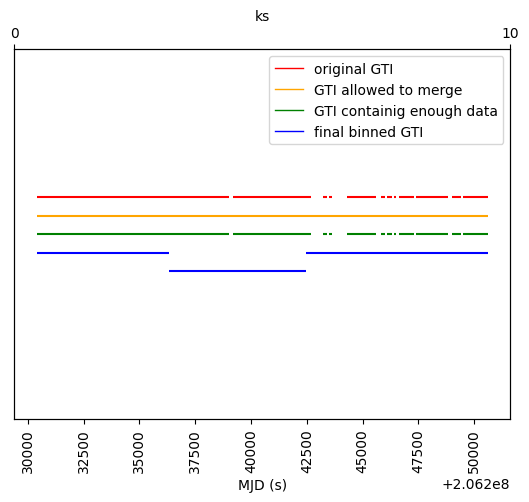

In [7]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots()

for index, row in def_new_gti_df.iterrows():
      
    if index % 2 == 0:  
        y_value = 1.18
    else:  
        y_value = 1.16
    ax.hlines(y_value, row['START'], row['STOP'], color='blue')
    

for index, row in grouped_new_gti.iterrows():
    ax.hlines(1.2, row['start'], row['stop'], color='green')    

for index, row in new_gti_df.iterrows():
    ax.hlines(1.22, row['start'], row['stop'], color='orange')
    
    

for index, row in gti_gen_rel.iterrows():
    
    global start_value
    global stop_value
    start_value = gti_gen_rel.loc[0]['start']
    stop_value = gti_gen_rel.loc[len(gti_gen_rel)-1]['stop']
    ax.hlines(1.24, row['start'], row['stop'], color='red')
    


# plt.xlim(np.min(3.3360e+08), np.max(3.3362e+08)) 





plt.ylim(np.min(1), np.max(1.4))
ax.set_xlabel('MJD (s)')
locs, labels = plt.xticks()
plt.setp(labels, rotation=90)
ax.set_yticklabels([])
ax.yaxis.set_visible(False)

legend_elements = [
    
    Line2D([0], [0], color='red', lw=1, label='original GTI'),
    Line2D([0], [0], color='orange', lw=1, label='GTI allowed to merge'),
    Line2D([0], [0], color='green', lw=1, label='GTI containig enough data'),
    Line2D([0], [0], color='blue', lw=1, label='final binned GTI')
    
]



ax2 = ax.twiny()

whole=int((stop_value-start_value)/1000)
sec_ax = np.arange(0,whole, 10)
ax2.set_xticks(sec_ax)
ax2.set_xlabel('ks')

ax.legend(handles=legend_elements, loc='upper right')

plt.savefig('MOS1_TRYING.png')
plt.show()


In [8]:
# whole=int((stop_value-start_value)/1000)
# sec_ax = np.linspace(0,whole, 10)


# print(sec_ax)
